# Torsional Spectra of Butane

The torsional spectrum of butane around the central C–C bond is computed with a neural network potential, by reducing the dynamics to the single torsional DOF. (see also section III C of the paper)

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Cartesian (42 DOFs) with 41 constraints (3 translations, 3 rotations, 13 bonds, 12 angles, 10 dihedrals) | MACE-ANI-CC | `ShakeRattle` | torsional angle $\phi$ (circle) |

- **Reduced dimensionality**: All the internal coordinates except the torsional angle $\phi$ of C–C–C–C are fixed by constraints, so that the dynamics is reduced to the single torsional DOF.

- **Time-dependent Eckart conditions**: The rotational constraints are imposed with `move_reference=True` , which removes the overall rotation for zero angular momentum $L = 0$ (see also [`InternalCoordinates`](https://tsumura-m.github.io/PySCIVR/pyscivr.coordinates.html#pyscivr.coordinates.InternalCoordinates)).

- **Potential**: The MACE-ANI-CC machine learning potential was used.

- **Precomputed data**: Since the trajectory calculation takes a long time, the trajectories and the Hessians are provided as precomputed data (see below), and this notebook computes the spectra from them.

- **Reference**: The peaks are compared with the eigenenergies of the 1D torsional Hamiltonian obtained by the discrete variable representation (DVR) (Appendix M of the paper).

## Precomputed data

The data are available at Zenodo: https://doi.org/10.5281/zenodo.22639777.
Download the following files and place them in the same directory as this notebook.

- `butane_trajs.tar.xz` (3.97 GB): trajectories and Hessians. Extract it by

```bash
  tar -xJf butane_trajs.tar.xz   # creates ./butane_trajs (5.21 GB)
```

- `butane_torsion_1d_pes.npz`: the metric $g(\phi)$ and the potential $V(\phi)$ along the torsion,
  used for the DVR reference.

The directory `butane_trajs` contains 500 trajectories and their Hessians ($i = 0, \ldots, 499$):

- `butane_noholonomy_{i}_traj.npz`: trajectory saved by `save_trajectory`.
- `butane_noholonomy_{i}_hess_int_20.npz`: projected Hessians evaluated every 20 steps, saved by `save_hessian`.

The $i$-th trajectory starts from the equilibrium structure (anti conformation) with the torsional kinetic energy
of $10 (i + 1)$ $\textrm{cm}^{-1}$, i.e., the torsional momenta are sampled uniformly in energy up to
5000 $\textrm{cm}^{-1}$. The trajectories were propagated for 1000 fs by `ShakeRattle` with the constraints
`COORD_CONST` defined below and the time step of 0.1 fs.

In [1]:
# import necessary libraries

import re
import time
from pathlib import Path

import numpy as np

from pyscivr.basis import get_overlap
from pyscivr.coordinates import InternalCoordinates
from pyscivr.save import load_hessian, load_trajectory
from pyscivr.scivr import get_action, get_lagrangian, get_prefactor, get_ta_spectrum_fft
from pyscivr.units import CmInv, FemtoSec, HBar
from pyscivr.utils import get_geom
from pyscivr.variations import make_jacobi_func, make_vari_propagator, propagate_variation, to_internal

## System and coordinates

`COORD_CONST` defines the 41 constraints used in the dynamics, and `COORD_ALL` adds the torsional angle to them, giving the full set of $3N = 42$ coordinates. The torsional angle C0–C1–C2–C3 is the only active coordinate.

## Initial states

The initial states are coherent states in $\phi$ centered at the anti conformation with the width of 0.2 rad.

The momentum centers are given by the torsional kinetic energies `K_ref`. With all the other internal coordinates fixed, the kinetic energy of the torsion is $K = \frac{G_{\text{eff}} p_\phi^2}{2}$, where $G_{\text{eff}}$ is the effective (inverse) metric of the torsion:

\begin{align*}
G_{\text{eff}}  = G_{AA} - G_{AC} G_{CC}^{-1} G_{CA}, \quad G = B M^{-1} B^T,
\end{align*}

with $A$ and $C$ denoting the active (torsion) and constrained coordinates.

## Calculation of spectra

`run` computes the spectra for all the initial states by the following steps for each trajectory:

1. Load the trajectory and restore the Lagrange multipliers.
2. Load the projected Hessians and interpolate them to all steps.
3. Propagate the variation and compute the monodromy matrix in the torsional angle.
4. Exclude the steps where the symplectic condition is not satisfied.
5. Compute the action, the prefactor and the overlap with each initial state, and the spectrum by the FFT.

The energy origin is the potential energy at the equilibrium structure (the initial point of all the trajectories).

In [2]:
# Constants
TRAJ_DIR = Path("./butane_trajs")

# equilibrium geometry of butane (anti conformation)
XYZSTR = """
C -1.782165997551355 0.7046770832233177 -0.35714805624899937
C -0.307337646395355 0.6970983276793177 0.02906807235300065
C 0.307337377499645 -0.6970984889146823 -0.029067048691999352
C 1.782166248497645 -0.7046769327506822 0.35714710091900065
H -2.360922424464355 0.0645086840323177 0.3111270081550006
H -2.205694947563355 1.7082196088783177 -0.31033219262899936
H -1.918495941808355 0.32979988334831767 -1.3731438030169993
H 0.252693249063645 1.3629886221333176 -0.6342421534349993
H -0.18693161525735502 1.0993804742503177 1.0393632762480005
H -0.252692582778355 -1.3629884147086824 0.6342443302950007
H 0.18693000317364497 -1.0993812487946824 -1.0393618525409993
H 2.2056947311936446 -1.7082197386196825 0.3103330163240006
H 1.918497721703645 -0.32979741827468234 1.3731417938860007
H 2.360922020616645 -0.0645103239996823 -0.3111302374959994
"""

SYMBOLS, POSI_REF, MASS = get_geom(XYZSTR)

BONDS = [(0, 1), (1, 2), (2, 3), (0, 4), (0, 5), (0, 6), (1, 7), (1, 8), (2, 9), (2, 10), (3, 11), (3, 12), (3, 13)]
ANGLES = [(0, 1, 2), (1, 2, 3), (1, 0, 4), (1, 0, 5), (1, 0, 6), (0, 1, 7), (0, 1, 8), (3, 2, 9), (3, 2, 10),
          (2, 3, 11), (2, 3, 12), (2, 3, 13)]
DIHEDRALS = [(2, 1, 0, 4), (2, 1, 0, 5), (2, 1, 0, 6), (4, 0, 1, 7), (4, 0, 1, 8), (11, 3, 2, 9), (11, 3, 2, 10),
             (1, 2, 3, 11), (1, 2, 3, 12), (1, 2, 3, 13)]
TORSION = (0, 1, 2, 3)

def make_coordinates(with_torsion):
    coord = InternalCoordinates(POSI_REF, MASS, move_reference=True)  # time-dependent Eckart conditions
    coord.add_translation()
    coord.add_rotation()
    for idx in BONDS:
        coord.add_bond(*idx)
    for idx in ANGLES:
        coord.add_angle(*idx)
    for idx in DIHEDRALS:
        coord.add_dihedral(*idx)
    if with_torsion:
        coord.add_dihedral(*TORSION)
    coord.build()
    return coord

COORD_CONST = make_coordinates(with_torsion=False) # 41 constraints for the dynamics
COORD_ALL = make_coordinates(with_torsion=True) # 42 coordinates for the transformation

TORSION_IDX = COORD_ALL.find_coordinate("dihedral", TORSION)[0]
ACTIVE_IDX = np.array([TORSION_IDX])
TOPOLOGIES = [COORD_ALL.topology[i] for i in ACTIVE_IDX]
 
JACOBI_FUNC, JACOBI_REV_FUNC, INTERNAL_FUNC, MONODROMY_FUNC = make_jacobi_func(COORD_ALL, ACTIVE_IDX)
 
pattern = re.compile(r"butane_noholonomy_(\d+)_traj\.npz")
TRAJ_FILES = sorted(TRAJ_DIR.glob("butane_noholonomy_*_traj.npz"), key=lambda p: int(pattern.fullmatch(p.name).group(1)))
assert TRAJ_FILES, f"No trajectory found in {TRAJ_DIR}. Download and extract the precomputed data first."
print(f"{len(TRAJ_FILES)} trajectories found.")

DT = 0.1 * FemtoSec  # DT = load_trajectory(TRAJ_FILES[0], coord_const=COORD_CONST)["dt"]


def get_torsional_momentum(K):
    """Torsional momentum giving the kinetic energy K [cm^-1] at the equilibrium structure."""
    B = np.asarray(COORD_ALL.get_const_grad(POSI_REF.reshape(-1)))
    G = B @ (B.T / np.repeat(MASS, 3)[:, None])
    a = TORSION_IDX
    c = np.setdiff1d(np.arange(len(G)), [a])
    G_eff = G[a, a] - G[a, c] @ np.linalg.solve(G[np.ix_(c, c)], G[c, a])
    return np.sqrt(2.0 * K * CmInv / G_eff)


def run(K_ref_list, gamma, fpath_list, n_fft, symp_err_tol=1e-2):

    judge_func = lambda symp_err: np.isfinite(symp_err) & (symp_err < symp_err_tol)

    posi_center, _ = INTERNAL_FUNC(POSI_REF, np.zeros_like(POSI_REF))   # anti conformation
    mome_centers = [np.array([get_torsional_momentum(K)]) for K in K_ref_list]
 
    n_sample = len(TRAJ_FILES)
    n_ref = len(K_ref_list)
    spectra = [0.0] * n_ref
    vari_propagator = make_vari_propagator(COORD_CONST, DT)

    t_start = time.perf_counter()
    for i, fpath in enumerate(TRAJ_FILES):
        # Load trajectory and Hessians
        traj = load_trajectory(fpath, coord_const=COORD_CONST)
        posi, mome = traj["posi"], traj["mome"]
        _, hess = load_hessian(fpath.with_name(fpath.name.replace("_traj.npz", "_hess_int_20.npz")),
                               COORD_ALL, posi, n_step=len(posi))

        # Get variation
        J_rev_init = JACOBI_REV_FUNC(posi[0], mome[0])
        vari = propagate_variation(vari_propagator, posi, mome, traj["lam"], traj["mu"], hess, J_rev_init)
        posi_int, mome_int, mono_int, symplectic_error = to_internal(MONODROMY_FUNC, posi, mome, vari)

        # Points with large symplectic error are treated as singularities
        valid = judge_func(symplectic_error)

        ener_ref = traj["potential_energy"][0] # equilibrium structure
        lag = get_lagrangian(traj["total_energy"], traj["potential_energy"], ener_ref=ener_ref)
        action = get_action(lag, DT)
        prefactor = get_prefactor(mono_int, gamma, valid=valid)

        for j in range(n_ref):
            overlap = get_overlap(TOPOLOGIES, posi_center, mome_centers[j], posi_int, mome_int, gamma)
            ener_grid, spec = get_ta_spectrum_fft(prefactor, overlap, action, DT, n_fft, valid=valid)
            spectra[j] += spec

        if i % 10 == 0:
            print(f"{i+1:6d} / {n_sample}, E = {(traj['total_energy'][0] - ener_ref) / CmInv:.1f} cm^-1, "
                  f"max symp error = {np.max(symplectic_error):.3e}, ({time.perf_counter() - t_start:.1f} sec)", flush=True)

    for j in range(n_ref):
        np.savez(fpath_list[j], ener_grid=ener_grid, spectrum=spectra[j] / n_sample)

Build complete: 41 coordinates
Build complete: 42 coordinates
500 trajectories found.


## Trajectories

Depending on the energy, the torsional motion changes its character: a localized vibration within the anti well, a large-amplitude motion across the three wells, and a full internal rotation.

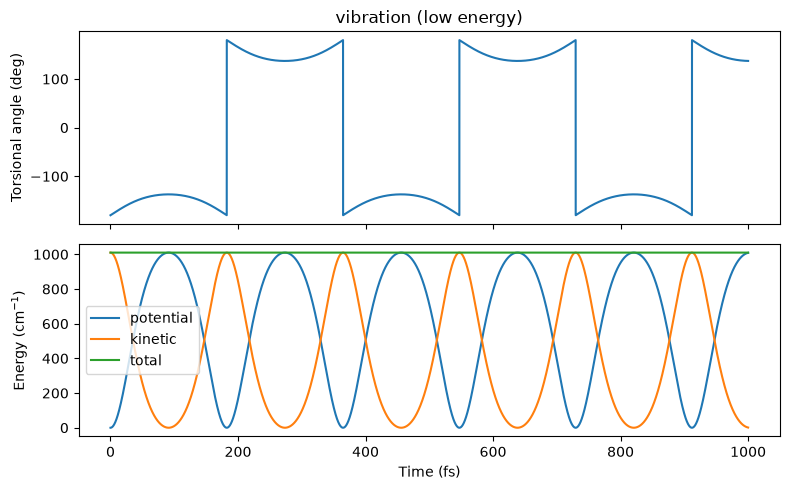

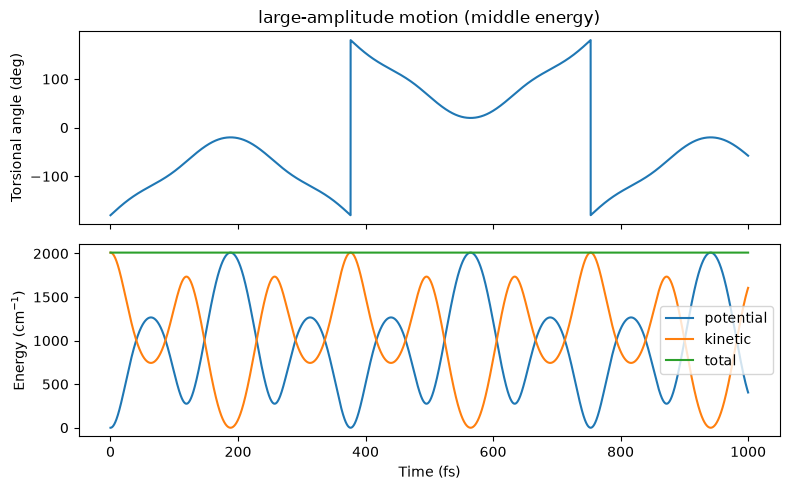

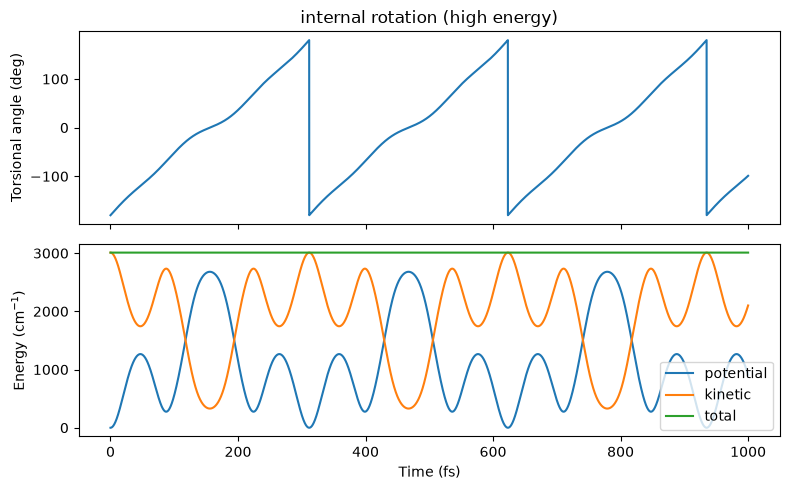

In [3]:
import matplotlib.pyplot as plt

def plot_trajectory(n, title):
    traj = np.load(TRAJ_FILES[n])
    t_fs = DT / FemtoSec * np.arange(len(traj["posi"]))
    torsion = np.asarray(COORD_ALL.get_value_batch(traj["posi"].reshape(len(t_fs), -1)))[:, TORSION_IDX]
    pot = traj["potential_energy"] - traj["potential_energy"][0]
    tot = traj["total_energy"] - traj["potential_energy"][0]
 
    fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
    axes[0].plot(t_fs, np.degrees(torsion))
    axes[0].set_ylabel("Torsional angle (deg)")
    axes[0].set_title(title)
    axes[1].plot(t_fs, pot / CmInv, label="potential")
    axes[1].plot(t_fs, (tot - pot) / CmInv, label="kinetic")
    axes[1].plot(t_fs, tot / CmInv, label="total")
    axes[1].set_ylabel(r"Energy (cm$^{-1}$)")
    axes[1].set_xlabel("Time (fs)")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_trajectory(100, "vibration (low energy)")
plot_trajectory(200, "large-amplitude motion (middle energy)")
plot_trajectory(300, "internal rotation (high energy)")

## Execute calculation

The total propagation time is 1000 fs.

In [4]:
if __name__ == "__main__":
    K_ref_list = [300.0, 1000.0, 1500.0, 2500.0, 3000.0, 4000.0]
    gamma = np.array([1.0 / (2 * 0.2**2)])   # sqrt(1 / 2 gamma) = 0.2 rad
    fpath_list = [f"butane_torsion_{K:.0f}_spectra.npz" for K in K_ref_list]
    run(K_ref_list, gamma, fpath_list, n_fft=2**19)

     1 / 500, E = 10.0 cm^-1, max symp error = 4.345e-13, (4.4 sec)
    11 / 500, E = 110.0 cm^-1, max symp error = 6.961e-13, (18.9 sec)
    21 / 500, E = 210.0 cm^-1, max symp error = 1.215e-12, (33.5 sec)
    31 / 500, E = 310.0 cm^-1, max symp error = 3.531e-12, (47.2 sec)
    41 / 500, E = 410.0 cm^-1, max symp error = 3.435e-12, (61.1 sec)
    51 / 500, E = 510.0 cm^-1, max symp error = 6.061e-12, (74.5 sec)
    61 / 500, E = 610.0 cm^-1, max symp error = 6.652e-12, (87.9 sec)
    71 / 500, E = 710.0 cm^-1, max symp error = 1.286e-11, (101.2 sec)
    81 / 500, E = 810.0 cm^-1, max symp error = 9.097e-12, (114.6 sec)
    91 / 500, E = 910.0 cm^-1, max symp error = 7.137e-12, (127.9 sec)
   101 / 500, E = 1010.0 cm^-1, max symp error = 2.969e-11, (142.1 sec)
   111 / 500, E = 1110.0 cm^-1, max symp error = 4.402e-11, (156.3 sec)
   121 / 500, E = 1210.0 cm^-1, max symp error = 6.792e-11, (170.0 sec)
   131 / 500, E = 1310.0 cm^-1, max symp error = 1.346e-10, (183.5 sec)
   141 / 50

## DVR reference

`butane_torsion_1d_pes.npz` contains the metric $g(\phi)$ [$1 / (\textrm{amu} \cdot \textrm{Å}^2)$] and the potential $V(\phi)$ [eV] on the grid of the torsional angle $\phi$ (1° spacing), where $\phi$ is measured from the anti conformation. They are interpolated by periodic cubic splines, and the eigenenergies of the 1D torsional Hamiltonian are obtained by the DVR (Appendix M of the paper).

In [5]:
from scipy.interpolate import CubicSpline

data = np.load("butane_torsion_1d_pes.npz") # load the potential and metric data
cs_g = CubicSpline(data["phi"], data["metric"], bc_type="periodic") # interpolate the metric data
cs_V = CubicSpline(data["phi"], data["pot"], bc_type="periodic") # interpolate the potential data

def dvr_1d(phi, g, V, K, dgm14=None):

    N = len(phi)
    k = np.arange(-K, K+1)

    a = g**-0.25
    b = g**-0.5
    ap = dgm14
    
    # X[j,k] = χ_k(φ_j)
    X = np.exp(1j*np.outer(phi, k)) / np.sqrt(2*np.pi)

    # U[j,k] = [(g^{-1/4})' + i k g^{-1/4}] χ_k
    U = (ap[:, None] + 1j*k[None, :]*a[:, None]) * X

    w = 2*np.pi/N

    T = 0.5*HBar**2 * w * (U.conj().T @ (b[:, None] * U))
    Vm = w * (X.conj().T @ (V[:, None] * X))

    H = T + Vm
    H = (H + H.conj().T)/2
    return np.linalg.eigvalsh(H), H

if __name__ == "__main__":
    N, K = 401, 200
    phi = 2 * np.pi * np.arange(N) / N
    E, H = dvr_1d(phi, cs_g(phi), cs_V(phi), K, dgm14=-0.25 * cs_g(phi, 1) / cs_g(phi)**1.25)
    E_dvr = E / CmInv # measured from the potential minimum (anti)
    print(f"First 101 DVR eigenenergies (cm^-1): {np.round(E_dvr[:101], 1)}")

First 101 DVR eigenenergies (cm^-1): [  63.1  187.9  309.6  345.6  345.6  428.1  483.   483.   543.1  615.4
  615.4  654.2  743.3  743.3  761.1  863.4  866.6  866.6  960.7  984.8
  984.8 1052.  1096.7 1096.7 1136.1 1198.  1199.2 1212.  1266.  1284.9
 1300.5 1335.7 1366.9 1396.  1429.4 1464.  1499.  1535.2 1572.4 1610.4
 1649.2 1688.7 1728.9 1769.8 1811.3 1853.4 1896.1 1939.4 1983.1 2027.3
 2072.  2117.  2162.5 2208.2 2254.2 2300.5 2346.7 2393.6 2439.3 2487.1
 2530.2 2580.8 2616.1 2675.3 2695.8 2771.8 2779.5 2871.4 2873.7 2975.1
 2975.7 3082.9 3083.1 3195.  3195.  3310.9 3310.9 3430.7 3430.7 3554.3
 3554.3 3681.4 3681.4 3812.1 3812.1 3946.3 3946.3 4084.  4084.  4225.1
 4225.1 4369.6 4369.6 4517.5 4517.5 4668.7 4668.7 4823.3 4823.3 4981.2
 4981.2]


K = 300
  peaks     (cm^-1): [187.7 310.5 430.1 546.5 660.4]
  deviation (cm^-1): [-0.2  0.8  2.   3.5  6.2]
K = 1000
  peaks     (cm^-1): [ 544.6  652.8  759.7  864.   964.5 1058.7 1140.1 1218.4 1286.4]
  deviation (cm^-1): [ 1.6 -1.4 -1.4  0.5  3.8  6.7  4.   6.3  1.5]
K = 1500
  peaks     (cm^-1): [1053.6 1136.3 1215.8 1427.7 1463.3 1498.9 1535.2 1572.7 1610.3 1649.1
 1689.2 1730.5 1771.9 1812.6 1854.6 1897.2 1941.8 1985.7 2031.5 2077.3
 2122.4]
  deviation (cm^-1): [ 1.6  0.2  3.8 -1.7 -0.7 -0.1 -0.   0.3 -0.1 -0.1  0.5  1.6  2.1  1.3
  1.1  1.1  2.4  2.5  4.1  5.3  5.4]
K = 2500
  peaks     (cm^-1): [2067.7 2114.2 2160.  2206.4 2253.5 2299.3 2347.  2393.5 2440.6 2486.4
 2532.8 2575.4 2669.  2766.9 2867.5 2973.7 3082.5 3191.9 3309.6]
  deviation (cm^-1): [-4.3 -2.9 -2.5 -1.8 -0.7 -1.2  0.3 -0.1  1.2 -0.7  2.6 -5.4 -6.4 -4.8
 -3.9 -1.3 -0.4 -3.  -1.3]
K = 3000
  peaks     (cm^-1): [2666.4 2765.7 2866.8 2971.8 3080.  3191.3 3307.7 3426.7 3549.5 3678.
 3809.7]
  deviation (cm^-1): [-8

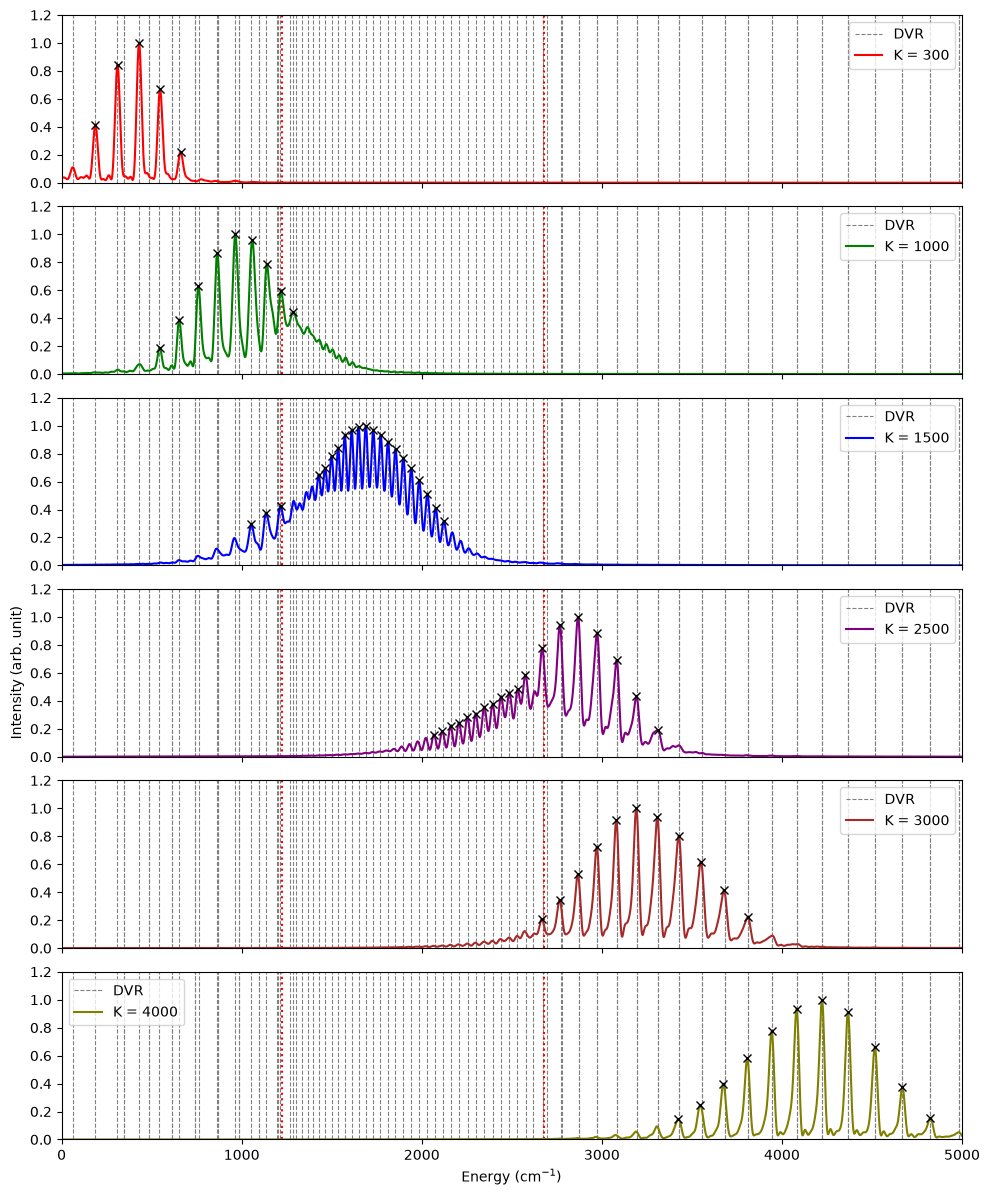

In [6]:
## Plot results

if __name__ == "__main__":
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks

    ener_max = 5000.0

    # DVR eigenenergies (from the DVR cell) and the barrier heights
    E_ref = E_dvr[E_dvr <= ener_max]
    barrier_gauche = 1226.0 # gauche barrier height (cm^-1)
    barrier_cis = 2680.5 # cis barrier height (cm^-1)

    # eigenstates of the DVR Hamiltonian

    fig, ax = plt.subplots(len(fpath_list), 1, figsize=(10, 2.0 * len(fpath_list)), sharex=True)
    colors = ['red', 'green', 'blue', 'purple', 'brown', 'olive']

    for i, fpath in enumerate(fpath_list):
        data = np.load(fpath)
        ener_grid = data["ener_grid"] / CmInv
        spectrum = data["spectrum"]
        spectrum /= np.max(spectrum[ener_grid <= ener_max])
        peaks, _ = find_peaks(spectrum, height=0.1, prominence=0.1, distance=10)
        peaks = peaks[ener_grid[peaks] <= ener_max]

        # nearest DVR level for each peak
        nearest = E_ref[np.argmin(np.abs(ener_grid[peaks][:, None] - E_ref[None, :]), axis=1)]
        print(f"K = {K_ref_list[i]:.0f}")
        print(f"  peaks     (cm^-1): {np.round(ener_grid[peaks], 1)}")
        print(f"  deviation (cm^-1): {np.round(ener_grid[peaks] - nearest, 1)}")

        ax[i].vlines(E_ref, 0.0, 1.2, color="gray", linestyle="--", linewidth=0.8, label="DVR")
        ax[i].vlines([barrier_gauche, barrier_cis], 0.0, 1.2, color="red", linestyle=":", linewidth=1.5)
        ax[i].plot(ener_grid, spectrum, color=colors[i], label=f"K = {K_ref_list[i]:.0f}")
        ax[i].plot(ener_grid[peaks], spectrum[peaks], "x", color="black")
        ax[i].set_ylim(0, 1.2)
        ax[i].legend()

    ax[-1].set_xlim(0, ener_max)
    ax[-1].set_xlabel(r"Energy (cm$^{-1}$)")
    ax[len(ax) // 2].set_ylabel("Intensity (arb. unit)")
    plt.tight_layout()
    plt.show()

The gray dashed lines are all the DVR eigenenergies, and the red dotted lines are the anti–gauche barrier
(1226.0 $\textrm{cm}^{-1}$) and the cis barrier (2680.5 $\textrm{cm}^{-1}$), taken from the paper.
Note that the DVR eigenenergies include the states localized in the two gauche wells below the anti–gauche barrier
(nearly degenerate pairs, e.g. 345.6 and 483.0 $\textrm{cm}^{-1}$). Since the initial states are centered at
the anti conformation, these states do not appear in the spectra; they are kept in the plot only for simplicity.

- **Quantitative agreement**: For all the initial states, the computed peaks agree with the nearest DVR eigenenergies within about 9 $\textrm{cm}^{-1}$, well below the intrinsic resolution of the propagation time (about 33 $\textrm{cm}^{-1}$ for 1000 fs).

- **Below the anti–gauche barrier** ($K = 300$, 1000 $\textrm{cm}^{-1}$): The peaks form a progression of the states localized in the anti well, with the spacing decreasing from about 120 to 80 $\textrm{cm}^{-1}$ due to the anharmonicity.

- **Between the two barriers** ($K = 1500$, 2500 $\textrm{cm}^{-1}$): The peaks form a dense progression with the spacing of about 35–47 $\textrm{cm}^{-1}$, corresponding to the large-amplitude motion across the three wells.

- **Above the cis barrier** ($K = 3000$, 4000 $\textrm{cm}^{-1}$): The spacing increases with energy (from about 100 to 155 $\textrm{cm}^{-1}$), corresponding to the internal rotation. Each peak corresponds to a nearly degenerate pair of DVR states (the clockwise and counterclockwise rotations).

The single torsional DOF is thus correctly extracted from the 42-dimensional Cartesian dynamics with the constraints,
and the SC-IVR spectra reproduce the qualitative change of the torsional motion over the whole energy range.